# Preface 
This notebook builds on from the last notebook. In the last notebook we looked at backprograpgation and how we train with matrix notation. The main issue is that we are manually spefiying the number of hidden layers often with small numbers 

My investigation is aking what happpens if extend the number of hidden layers and number of neurone in one hidden layer 

- How would backpropgration work?

- Does it resemble the way pytorch might do it under the hood?

- This is an optional task for Izaan Understanding

# Step 1 — Load our dataset
The breast cancer dataset contains 569 observations, each with 30 numerical features, and a binary target.

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", data.target_names)

X shape: (569, 30)
y shape: (569,)
Classes: ['malignant' 'benign']


# Step 2 — Split and standardise

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Transpose so each observation is a column - X train is 30 x 455 and W is 16 x 30. Transpose X train gives us 30 x 455 and W is 16 x 30. When we multiply W @ X_train, we get 16 x 455 which is what we want. If we didn't transpose, we would have 455 x 30 and W is 16 x 30. When we multiply W @ X_train, we would get an error because the inner dimensions don't match (30 != 16). So we transpose X_train to make sure the inner dimensions match when we multiply with W.
X_train = X_train.T
X_test = X_test.T

# Targets as row vectors
y_train = y_train.reshape(1, -1)
y_test = y_test.reshape(1, -1)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# shape follows a convention (number of outputs, number of observations)

X_train: (30, 455)
y_train: (1, 455)
X_test: (30, 114)
y_test: (1, 114)


# Step 3 — Initialise weights and biases
Our architecture will be:

30 -> 16 -> 8 -> 1

But we want the code to work with any number of hidden layers and neurons (ideally)

In [3]:
def initialise_network(n_features, hidden_layers, seed=42):
    rng = np.random.default_rng(seed) # we are importing random becuase the weight will be initialised randomly and we want to be able to reproduce the results

    architecture = [n_features] + hidden_layers + [1] # python concantention [30] + [16, 8] + [1] = [30, 16, 8, 1]

    weights = [] # initialise empty list to store weights
    biases = [] # initialize empty list to store biases

    for layer in range(1, len(architecture)):
        n_inputs = architecture[layer - 1] # the number of inputs to the current layer is the number of neurons in the previous layer
        n_neurons = architecture[layer] # the number of neurons in the current layer is the number of neurons in the current layer

        if layer < len(architecture) - 1:
            scale = np.sqrt(2 / n_inputs) #wth???
        else:
            scale = np.sqrt(1 / n_inputs) #wth???

        W = rng.standard_normal((n_neurons, n_inputs)) * scale # why do we multiply by scale?
        b = np.zeros((n_neurons, 1)) # zero initalially we want to test the effect of the weights and not the bias

        weights.append(W) # the weight matrix for the current layer is added to the list of weights
        biases.append(b) # the bias vector for the current layer is added to the list of biases

    return weights, biases

In [22]:
weights, biases = initialise_network(
    n_features=30,
    hidden_layers=[16, 8]
)

for i, (W, b) in enumerate(zip(weights, biases), start=1):
    print(f"Layer {i}: W={W.shape}, b={b.shape}")
    
print(len(weights[0]))

Layer 1: W=(16, 30), b=(16, 1)
Layer 2: W=(8, 16), b=(8, 1)
Layer 3: W=(1, 8), b=(1, 1)
16


In [5]:
def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

In [6]:
def forward(X, weights, biases):
    activations = [X] # initialize list of activations with input data
    weighted_sums = [] # stores the weighted sums (Z) for each layer. Why do we need to store these?

    A = X

    for layer in range(len(weights)): # len weights represents the number of layers in the network
        W = weights[layer] # extract the weight matrix for the current layer
        b = biases[layer] # extract the bias vector for the current layer

        Z = W @ A + b # compute the weighted sum for the current layer

        if layer == len(weights) - 1:
            A = sigmoid(Z) # compute the activation for the output layer using the sigmoid function. Remember that the output layer has a different activation function than the hidden layers
        else:
            A = relu(Z) # compute the activation for the hidden layers using the ReLU function

        weighted_sums.append(Z) # store the weighted sum for the current layer
        activations.append(A) # store the activation for the current layer

    return activations, weighted_sums

In [7]:
def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-12

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [8]:
activations, weighted_sums = forward(
    X_train, weights, biases
)

y_pred = activations[-1]

loss = binary_cross_entropy(y_train, y_pred)

print("Initial BCE loss:", loss)

Initial BCE loss: 0.7852400030392699


In [9]:
def relu_derivative(Z):
    return (Z > 0).astype(float)

In [1]:
def backward_iterative(weights, activations, weighted_sums, y_true):
    m = y_true.shape[1]
    L = len(weights)

    dW = [None] * L
    db = [None] * L

    dJ_dZ = activations[-1] - y_true

    for layer in reversed(range(L)):
        dW[layer] = (dJ_dZ @ activations[layer].T) / m
        db[layer] = np.sum(dJ_dZ, axis=1, keepdims=True) / m

        if layer > 0:
            dJ_dZ = (
                weights[layer].T @ dJ_dZ
            ) * relu_derivative(weighted_sums[layer - 1])

    return dW, db

In [10]:
def backward_recursive(weights, activations, weighted_sums, y_true):

    m = y_true.shape[1]
    L = len(weights)

    dW = [None] * L
    db = [None] * L

    def backward(layer):

        # Base case: output layer
        if layer == L - 1:
            delta = activations[-1] - y_true

        else:
            # Recursively calculate the next layer's delta
            next_delta = backward(layer + 1)

            delta = (
                weights[layer + 1].T @ next_delta
            ) * relu_derivative(weighted_sums[layer])

        # Calculate parameter gradients
        dW[layer] = (
            delta @ activations[layer].T
        ) / m

        db[layer] = np.sum(
            delta, axis=1, keepdims=True
        ) / m

        return delta

    backward(0)

    return dW, db

In [11]:
dW, db = backward_recursive(
    weights,
    activations,
    weighted_sums,
    y_train
)

for i in range(len(weights)):
    print(f"Layer {i + 1}")
    print(f"  W shape:  {weights[i].shape}")
    print(f"  dW shape: {dW[i].shape}")
    print(f"  b shape:  {biases[i].shape}")
    print(f"  db shape: {db[i].shape}")

Layer 1
  W shape:  (16, 30)
  dW shape: (16, 30)
  b shape:  (16, 1)
  db shape: (16, 1)
Layer 2
  W shape:  (8, 16)
  dW shape: (8, 16)
  b shape:  (8, 1)
  db shape: (8, 1)
Layer 3
  W shape:  (1, 8)
  dW shape: (1, 8)
  b shape:  (1, 1)
  db shape: (1, 1)


In [12]:
def gradient_check(weights, biases, X, y, dW, epsilon=1e-5):

    layer = len(weights) - 1

    row = 0
    col = 0

    original_weight = weights[layer][row, col]

    # Calculate loss with slightly increased weight
    weights[layer][row, col] = original_weight + epsilon

    activations_plus, _ = forward(X, weights, biases)
    loss_plus = binary_cross_entropy(y, activations_plus[-1])

    # Calculate loss with slightly decreased weight
    weights[layer][row, col] = original_weight - epsilon

    activations_minus, _ = forward(X, weights, biases)
    loss_minus = binary_cross_entropy(y, activations_minus[-1])

    # Restore original weight
    weights[layer][row, col] = original_weight

    numerical_gradient = (
        loss_plus - loss_minus
    ) / (2 * epsilon)

    backprop_gradient = dW[layer][row, col]

    print("Numerical gradient:", numerical_gradient)
    print("Backprop gradient: ", backprop_gradient)
    print("Absolute difference:",
          abs(numerical_gradient - backprop_gradient))

In [13]:
gradient_check(
    weights,
    biases,
    X_train,
    y_train,
    dW
)

Numerical gradient: -0.09204341310242724
Backprop gradient:  -0.09204341310217261
Absolute difference: 2.5462965069777965e-13


In [14]:
def update_parameters(weights, biases, dW, db, learning_rate):

    for layer in range(len(weights)):
        weights[layer] -= learning_rate * dW[layer]
        biases[layer] -= learning_rate * db[layer]

    return weights, biases

In [15]:
def train(X, y, weights, biases, epochs=1000, learning_rate=0.01):

    history = []

    for epoch in range(epochs):

        # Forward propagation
        activations, weighted_sums = forward(X, weights, biases)

        # Calculate loss
        loss = binary_cross_entropy(y, activations[-1])

        # Recursive backpropagation
        dW, db = backward_recursive(
            weights,
            activations,
            weighted_sums,
            y
        )

        # Gradient descent
        weights, biases = update_parameters(
            weights, biases, dW, db, learning_rate
        )

        history.append(loss)

        if epoch % 100 == 0:
            print(f"Epoch {epoch}: Loss = {loss:.6f}")

    return weights, biases, history

In [16]:
weights, biases, history = train(
    X_train,
    y_train,
    weights,
    biases,
    epochs=1000,
    learning_rate=0.01
)

Epoch 0: Loss = 0.785240
Epoch 100: Loss = 0.528450
Epoch 200: Loss = 0.430025
Epoch 300: Loss = 0.347532
Epoch 400: Loss = 0.270165
Epoch 500: Loss = 0.205736
Epoch 600: Loss = 0.161435
Epoch 700: Loss = 0.133002
Epoch 800: Loss = 0.113996
Epoch 900: Loss = 0.099502


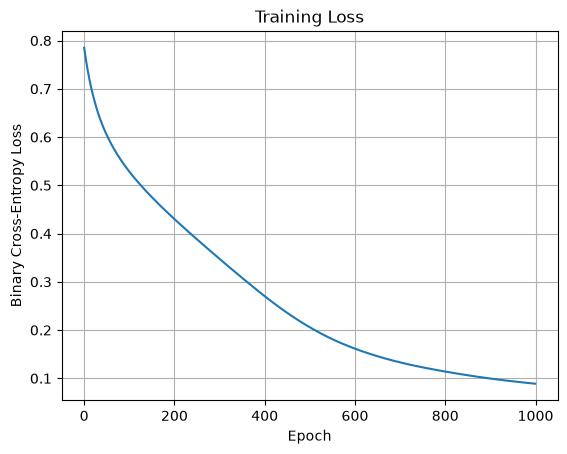

In [17]:
import matplotlib.pyplot as plt

plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

In [18]:
# Forward propagation on unseen test data
test_activations, _ = forward(X_test, weights, biases)

# Predicted probabilities
y_prob = test_activations[-1]

# Convert probabilities into binary classifications
y_pred = (y_prob >= 0.5).astype(int)

print("Predictions shape:", y_pred.shape)
print("First 10 probabilities:", y_prob[0, :10])
print("First 10 predictions:", y_pred[0, :10])

Predictions shape: (1, 114)
First 10 probabilities: [2.31078735e-05 9.94373982e-01 2.09992122e-02 5.09260974e-01
 6.40553587e-06 9.32297534e-01 9.96674614e-01 5.61381652e-05
 2.68756077e-03 1.28253989e-07]
First 10 predictions: [0 1 0 1 0 1 1 0 0 0]


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true = y_test.flatten()
y_pred_flat = y_pred.flatten()

print("Accuracy: ", accuracy_score(y_true, y_pred_flat))
print("Precision:", precision_score(y_true, y_pred_flat))
print("Recall:   ", recall_score(y_true, y_pred_flat))
print("F1-score: ", f1_score(y_true, y_pred_flat))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred_flat,
    target_names=["Malignant", "Benign"]
))

Accuracy:  0.9649122807017544
Precision: 0.9594594594594594
Recall:    0.9861111111111112
F1-score:  0.9726027397260274

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.93      0.95        42
      Benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



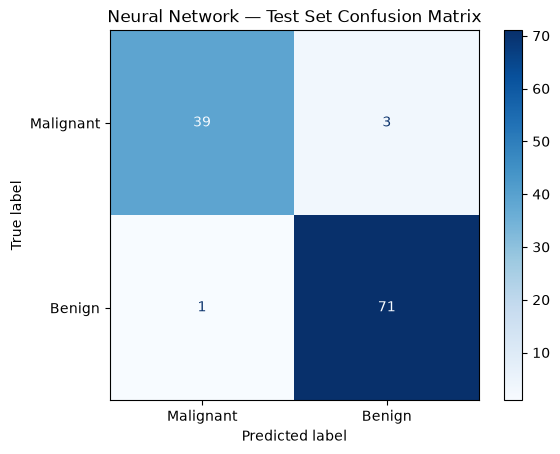

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred_flat,
    display_labels=["Malignant", "Benign"],
    cmap="Blues"
)

plt.title("Neural Network — Test Set Confusion Matrix")
plt.show()

In [21]:
train_activations, _ = forward(X_train, weights, biases)

train_loss = binary_cross_entropy(
    y_train, train_activations[-1]
)

test_loss = binary_cross_entropy(
    y_test, y_prob
)

print(f"Training BCE: {train_loss:.4f}")
print(f"Test BCE:     {test_loss:.4f}")

Training BCE: 0.0888
Test BCE:     0.1210
